# La autoridad de un tool call no debe depender del texto de su ruta

## Resumen
En 56 fixtures de intento de escape por política, prefijo textual lee 56 canarios externos, resolver-antes-de-abrir lee 24 y descriptor anclado lee cero. El control anclado sólo resuelve 16/24 solicitudes benignas porque rechaza aliases symlink internos. Son casos sintéticos controlados, no tasas de éxito de ataques reales ni una certificación de seguridad.

## Contexto y métodos

### Modelo de amenaza
El request puede proponer rutas y presupuestos, pero no root, código Python ni permisos. Un grant confiable abre un descriptor raíz. El broker permite sólo read_text, valida campos exactos y bytes, y niega otros tools. En Unix recorre cada componente relativo con dir_fd/O_NOFOLLOW; sólo lee un archivo regular UTF-8, niega nlink distinto de uno y no escribe.

Los dos baselines comparten esquema y límite de bytes: uno acepta prefijo textual y otro valida realpath antes de abrir por pathname. El hook de prueba cambia un padre o hoja entre validación y uso. Está fuera del request y no se expone a un modelo.

### Límites
Los descriptores conservan identidad del objeto abierto, no su pertenencia actual a una ruta tras renames. Sin mounts hostiles, hardlink races, cambios maliciosos de contenido, auth multi-tenant ni LLM real. Los casos temporales nunca usan datos del usuario. Fuentes OWASP/MITRE/Python/Linux en referencias.bib.

## Configuración y evidencia
Doce escenarios y ocho variantes de nombre/contenido. Estas repeticiones deterministas no son muestras independientes de ataques naturales; no se calculan intervalos binomiales de seguridad general.

In [1]:
import json
from pathlib import Path
from IPython.display import display, SVG
r=json.loads(Path("results/summary.json").read_text())
r["config"]

Out[0]: 
{'seeds': [0, 1, 2, 3, 4, 5, 6, 7],
 'cases': ['safe',
  'nested',
  'internal_alias',
  'traversal',
  'prefix_sibling',
  'symlink_file',
  'symlink_dir',
  'race_parent',
  'race_leaf',
  'hardlink',
  'wrong_tool',
  'overbudget'],
 'max_read_bytes': 4096,
 'max_path_depth': 16,
 'max_path_characters': 256,
 'hypothesis': 'anchored_fd has zero outside-canary reads in seven escape scenarios; resolve_then_open leaks under two deterministic check/use interleavings; anchored utility denial limited to internal alias',
 'threat_model': 'untrusted read requests and symlink replacements in temporary fixtures; trusted root grant; no hostile mounts/kernel/hardlink creation-unlink races',
 'dataset': 'entirely synthetic temporary directories; no LLM, network, user files or real credentials',
 'selection': [{'idea': 'anchored read-only tool broker with TOCTOU audit',
   'decision': 'selected',
   'reason': 'new pilar08 S1 gap and deterministic executable security boundary'},
  {'idea'

## Experimento mínimo vivo
El canario se crea dentro del TemporaryDirectory del test. La misma sustitución de padre se inyecta en ambos métodos; no se imprime el contenido leído.

In [2]:
import tempfile
from src.broker import ReadBroker, Denied
from src.fixtures import setup
for mode in ("resolve_then_open","anchored_fd"):
    with tempfile.TemporaryDirectory() as tmp:
        root,request,hook,safe,canary=setup(Path(tmp),"race_parent",17)
        with ReadBroker(root,mode) as broker:
            content=broker.read(request,fault_hook=hook)
        print(mode,"outside_canary_read=",content==canary,"granted_object_read=",content==safe)
print("Agregados:")
for row in r["summary"]:
    print(row)

resolve_then_open outside_canary_read= True granted_object_read= False
anchored_fd outside_canary_read= False granted_object_read= True
Agregados:
{'mode': 'prefix', 'requests': 96, 'escape_fixtures': 56, 'escaped_reads': 56, 'escape_rate': 1.0, 'benign_requests': 24, 'benign_safe_reads': 24, 'utility_denial_rate': 0.0, 'mean_seconds': 7.116103125189473e-05, 'max_python_peak_bytes': 5164}
{'mode': 'resolve_then_open', 'requests': 96, 'escape_fixtures': 56, 'escaped_reads': 24, 'escape_rate': 0.42857142857142855, 'benign_requests': 24, 'benign_safe_reads': 24, 'utility_denial_rate': 0.0, 'mean_seconds': 0.0002233026249906326, 'max_python_peak_bytes': 5330}
{'mode': 'anchored_fd', 'requests': 96, 'escape_fixtures': 56, 'escaped_reads': 0, 'escape_rate': 0.0, 'benign_requests': 24, 'benign_safe_reads': 16, 'utility_denial_rate': 0.3333333333333333, 'mean_seconds': 5.388403124702753e-05, 'max_python_peak_bytes': 4993}


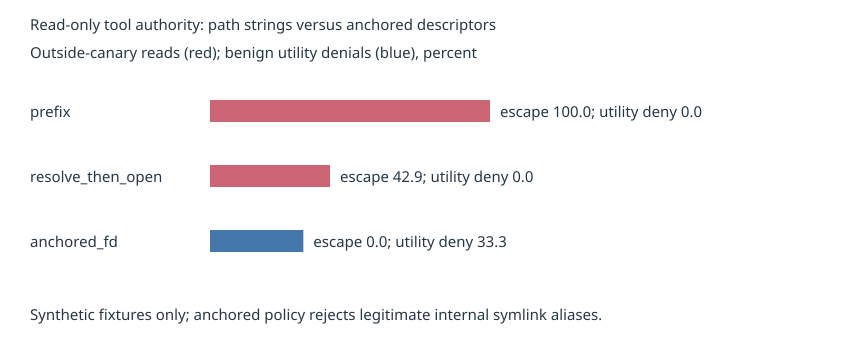

In [3]:
display(SVG(filename="results/authority.svg"))

### Interpretación
Rojo representa lectura del recurso canario no autorizado; azul representa pérdida de utilidad por la política sin symlinks. Negar todo también daría cero escapes, pero el test exige lecturas directas/nested correctas y evidencia el coste de aliases. Resolver rutas primero no hace atómica su apertura posterior.

In [4]:
rows={x["mode"]:x for x in r["summary"]}
assert rows["anchored_fd"]["escaped_reads"]==0
assert rows["anchored_fd"]["benign_safe_reads"]==16
assert rows["resolve_then_open"]["escaped_reads"]==24
assert rows["prefix"]["escaped_reads"]==56
assert rows["anchored_fd"]["utility_denial_rate"]>0
print("Hipótesis local confirmada; seguridad general y modelos LLM no evaluados.")
r["environment"]

Hipótesis local confirmada; seguridad general y modelos LLM no evaluados.
Out[0]: 
{'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9}


## Conclusiones y siguiente iteración
Se limita autoridad mediante controles externos al modelo, en lugar de pedirle que interprete permisos. La suite falsifica dos implementaciones de chequeo de ruta y demuestra un control pequeño con límites explícitos. Próximo paso: comparar openat2 con políticas de mounts y definir autorizaciones multi-tenant, antes de evaluar tool calls generadas por LLM. Notebook ejecutado IPython in-process; no kernel aislado.